In [1]:

import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    silhouette_score
)


In [2]:

# Load datasets
train = pd.read_csv("../training_image_features.csv")
test = pd.read_csv("../testing_image_features.csv")

TARGET = "Condition_Class"
CLASSES = ["Excellent", "Good", "Fair", "Poor"]

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

print("\nTraining Dataset:")
display(train.head())


Training Dataset Shape: (10058, 43)
Testing Dataset Shape: (3224, 43)

Training Dataset:


,Sample_ID,Image_ID,Material_Type,Material_Subtype,Source,Exposure_Type,Crack_Level,Surface_Damage,Breakage_Level,Discoloration_Level,...,dark_pixel_ratio,bright_pixel_ratio,mean_hue,mean_saturation,saturation_std,contour_area,contour_perimeter,circularity,solidity,extent
0,TRAINING_00001,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,5,4.0,3,High,...,0.007217,0.250679,16.328107,103.354121,34.788167,24050.0,2086.576892,0.069415,0.645430,0.460799
1,TRAINING_00002,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,3.5,2,Moderate,...,0.074190,0.022587,25.591271,61.989752,18.395387,15420.0,665.754394,0.437186,0.903736,0.635038
2,TRAINING_00003,1.jpg,tile,Standard,Demolition_Site,Exterior_Weathered,2,3.2,2,High,...,0.030780,0.677715,26.294677,69.389570,18.294682,25750.5,698.114786,0.663960,0.976915,0.710672
3,TRAINING_00004,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,4,3.2,3,Moderate,...,0.230558,0.033828,41.511739,83.602221,28.279230,11908.5,1237.869180,0.097660,0.761900,0.616573
4,TRAINING_00005,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,4.0,3,High,...,0.136304,0.361647,29.703155,61.738122,22.880945,16204.5,963.702659,0.219260,0.837139,0.603520


In [3]:

# Exclude target-related scores
exclude = {
    "Condition_Score",
    "Damage_Score",
    "Alternative_Use_Suitability"
}

# Select numeric image features
features = [
    col for col in train.select_dtypes(include=np.number).columns
    if col not in exclude
]

print("Number of Features:", len(features))
print("\nSelected Features:")
print(features)


Number of Features: 26

Selected Features:
['Crack_Level', 'Surface_Damage', 'Breakage_Level', 'Deformation_Level', 'pixel_img_width', 'pixel_img_height', 'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density', 'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast', 'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue', 'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter', 'circularity', 'solidity', 'extent']


In [4]:

# Extract selected features
X_train = train[features].replace([np.inf, -np.inf], np.nan)
X_test = test[features].replace([np.inf, -np.inf], np.nan)

# Handle missing values
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Standardize features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)
print("Preprocessing Completed Successfully")


Training Data Shape: (10058, 26)
Testing Data Shape: (3224, 26)
Preprocessing Completed Successfully


In [5]:

# Initialize Gaussian Mixture Model
model = GaussianMixture(
    n_components=4,
    covariance_type="diag",
    random_state=42,
    n_init=3,
    max_iter=200,
    reg_covar=1e-6
)

# Fit GMM on training data
model.fit(X_train)

# Predict training and testing clusters
train_clusters = model.predict(X_train)
test_clusters = model.predict(X_test)

print("GMM Clustering Completed")

print("\nCluster Distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())


GMM Clustering Completed

Cluster Distribution:
0    2213
1    2838
2    1879
3    3128
Name: count, dtype: int64


In [6]:

# Map clusters to majority condition classes
cluster_mapping = {}

for cluster in range(4):
    labels = train.loc[
        train_clusters == cluster, TARGET
    ]

    if len(labels) > 0:
        cluster_mapping[cluster] = labels.mode().iloc[0]
    else:
        cluster_mapping[cluster] = train[TARGET].mode().iloc[0]

print("Cluster to Condition Mapping:")
print(cluster_mapping)


Cluster to Condition Mapping:
{0: 'Fair', 1: 'Fair', 2: 'Fair', 3: 'Fair'}


In [7]:

# Predict testing classes
y_pred = np.array([
    cluster_mapping[c] for c in test_clusters
])

y_test = test[TARGET].astype(str)

print("Predicted Classes:")
print(pd.Series(y_pred).value_counts())

print("\nActual Classes:")
print(y_test.value_counts())


Predicted Classes:
Fair    3224
Name: count, dtype: int64

Actual Classes:
Condition_Class
Fair         2193
Good          716
Poor          274
Excellent      41
Name: count, dtype: int64


In [8]:

# Evaluate GMM
print("Gaussian Mixture Model")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=CLASSES,
    zero_division=0
))

# Evaluate cluster separation
silhouette = silhouette_score(
    X_train,
    train_clusters,
    sample_size=2000,
    random_state=42
)

print("Silhouette Score:", silhouette)

print("BIC:", model.bic(X_train))
print("AIC:", model.aic(X_train))

print("Model Converged:", model.converged_)
print("Number of Iterations:", model.n_iter_)


Gaussian Mixture Model
Accuracy: 0.6802109181141439

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.00      0.00      0.00        41
        Good       0.00      0.00      0.00       716
        Fair       0.68      1.00      0.81      2193
        Poor       0.00      0.00      0.00       274

    accuracy                           0.68      3224
   macro avg       0.17      0.25      0.20      3224
weighted avg       0.46      0.68      0.55      3224

Silhouette Score: 0.10089718560945682
BIC: 239519.78392749367
AIC: 237997.18184436325
Model Converged: True
Number of Iterations: 22


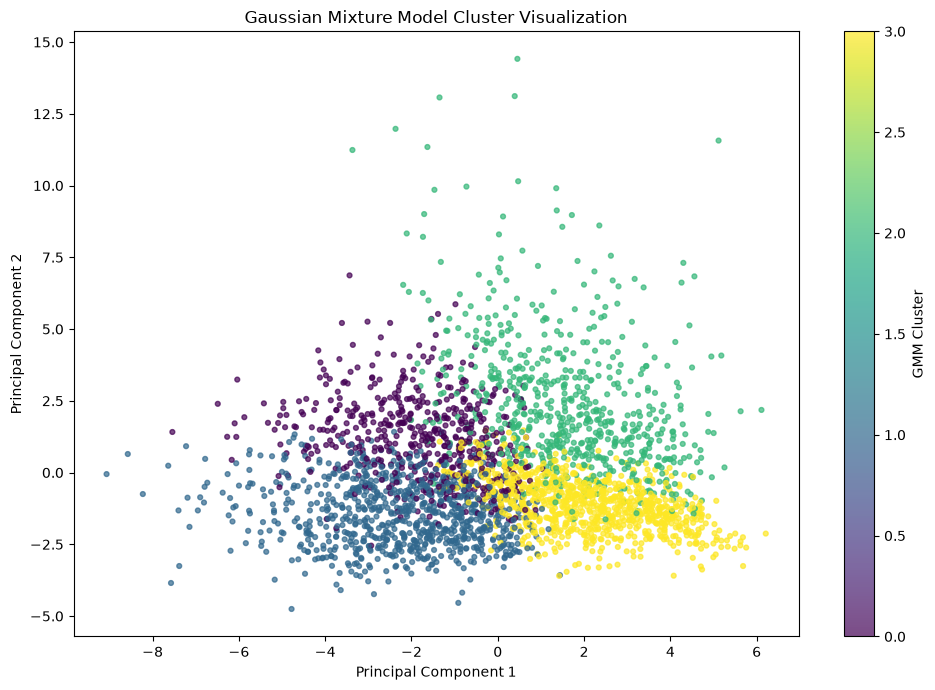

Samples visualized: 3000


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

sample_size = min(3000, len(X))
indices = np.random.RandomState(42).choice(
    len(X), sample_size, replace=False
)

model = GaussianMixture(
    n_components=4,
    covariance_type="diag",
    random_state=42,
    n_init=1,
    max_iter=100,
    reg_covar=1e-5
)

model.fit(X[indices])
clusters = model.predict(X[indices])

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X[indices])

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=clusters, cmap="viridis",
    s=12, alpha=0.7
)

plt.title("Gaussian Mixture Model Cluster Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="GMM Cluster")
plt.tight_layout()
plt.show()

print("Samples visualized:", sample_size)


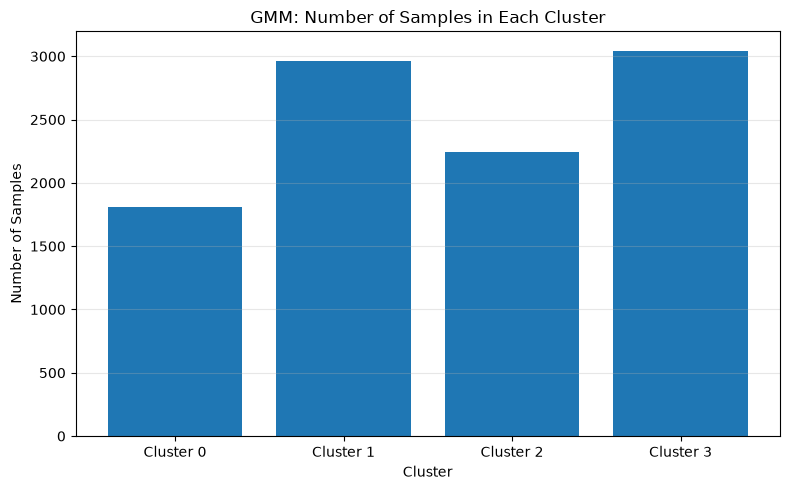

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

sample_size = min(3000, len(X))
indices = np.random.RandomState(42).choice(
    len(X), sample_size, replace=False
)

model = GaussianMixture(
    n_components=4,
    covariance_type="diag",
    random_state=42,
    n_init=1,
    max_iter=100,
    reg_covar=1e-5
)

model.fit(X[indices])
clusters = model.predict(X)

counts = np.bincount(clusters, minlength=4)

plt.figure(figsize=(8, 5))
plt.bar([f"Cluster {i}" for i in range(4)], counts)

plt.title("GMM: Number of Samples in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Samples")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


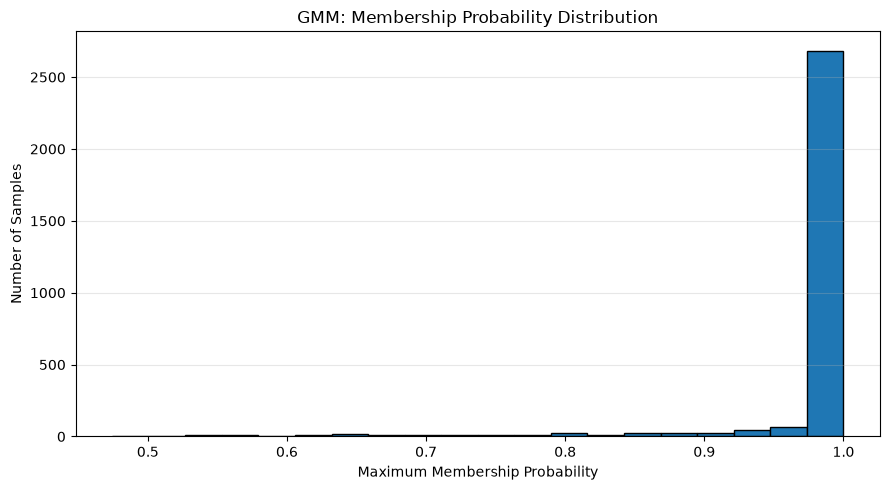

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

sample_size = min(3000, len(X))
indices = np.random.RandomState(42).choice(
    len(X), sample_size, replace=False
)

model = GaussianMixture(
    n_components=4,
    covariance_type="diag",
    random_state=42,
    n_init=1,
    max_iter=100,
    reg_covar=1e-5
)

model.fit(X[indices])

probabilities = model.predict_proba(X[indices])
maximum_probabilities = probabilities.max(axis=1)

plt.figure(figsize=(9, 5))
plt.hist(maximum_probabilities, bins=20, edgecolor="black")

plt.title("GMM: Membership Probability Distribution")
plt.xlabel("Maximum Membership Probability")
plt.ylabel("Number of Samples")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


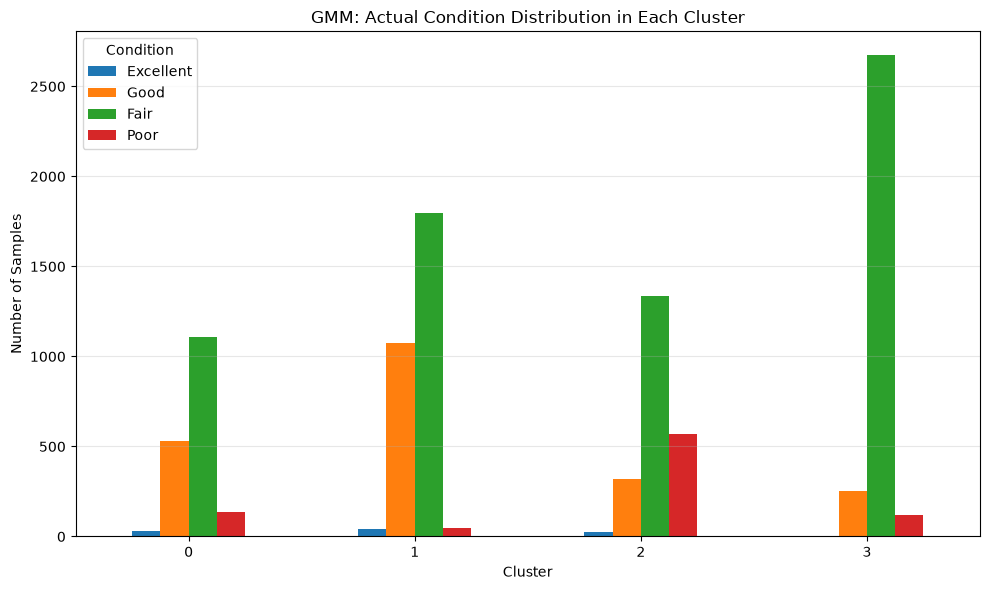

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

sample_size = min(3000, len(X))
indices = np.random.RandomState(42).choice(
    len(X), sample_size, replace=False
)

model = GaussianMixture(
    n_components=4,
    covariance_type="diag",
    random_state=42,
    n_init=1,
    max_iter=100,
    reg_covar=1e-5
)

model.fit(X[indices])
clusters = model.predict(X)

distribution = pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    train_graph["Condition_Class"].reset_index(drop=True)
)

distribution = distribution.reindex(
    columns=["Excellent", "Good", "Fair", "Poor"],
    fill_value=0
)

distribution.plot(kind="bar", figsize=(10, 6))

plt.title("GMM: Actual Condition Distribution in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.legend(title="Condition")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


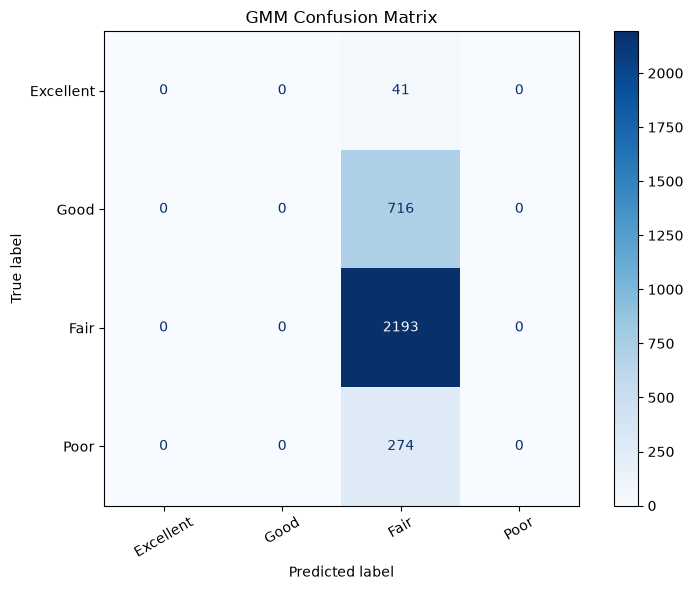

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

train_graph = pd.read_csv("../training_image_features.csv")
test_graph = pd.read_csv("../testing_image_features.csv")

target = "Condition_Class"
classes = ["Excellent", "Good", "Fair", "Poor"]

excluded = [
    target, "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X_train = train_graph[features].replace([np.inf, -np.inf], np.nan)
X_test = test_graph.reindex(columns=features).replace(
    [np.inf, -np.inf], np.nan
)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

sample_size = min(3000, len(X_train))
indices = np.random.RandomState(42).choice(
    len(X_train), sample_size, replace=False
)

model = GaussianMixture(
    n_components=4,
    covariance_type="diag",
    random_state=42,
    n_init=1,
    max_iter=100,
    reg_covar=1e-5
)

model.fit(X_train[indices])

train_clusters = model.predict(X_train)
test_clusters = model.predict(X_test)

y_train = train_graph[target].reset_index(drop=True)
mapping = {}

for cluster in range(4):
    labels = y_train[train_clusters == cluster]
    mapping[cluster] = labels.mode().iloc[0] if len(labels) else "Fair"

predictions = pd.Series(test_clusters).map(mapping)

cm = confusion_matrix(
    test_graph[target], predictions, labels=classes
)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    cm, display_labels=classes
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title("GMM Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
